In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

In [2]:
superSeed = 42
torch.manual_seed(superSeed)
np.random.seed(superSeed)

In [3]:
import kagglehub

path = kagglehub.dataset_download("blastchar/telco-customer-churn")
print("Dataset downloaded to:", path)

df = pd.read_csv(path + "/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.head())


Dataset downloaded to: C:\Users\nbadr\.cache\kagglehub\datasets\blastchar\telco-customer-churn\versions\1
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber opt

In [4]:
df = df.drop("customerID", axis=1)

# TotalCharges has whitespace → convert to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Handle missing values
df = df.dropna()

# Split target from features
y = df["Churn"].map({"Yes": 1, "No": 0}).values
X = df.drop("Churn", axis=1)


# ----------------------------------------------------------
# 3. ENCODE CATEGORICAL FEATURES
# ----------------------------------------------------------

# Identify categorical + numerical columns
categorical_cols = X.select_dtypes(include=["object"]).columns
numeric_cols = X.select_dtypes(exclude=["object"]).columns

# One-hot encode categorical columns
encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
X_cat = encoder.fit_transform(X[categorical_cols])

# Scale numeric columns
scaler = StandardScaler()
X_num = scaler.fit_transform(X[numeric_cols])

# Combine both
X_processed = np.hstack([X_num, X_cat])

print("Final feature shape:", X_processed.shape)

Final feature shape: (7032, 45)


In [5]:
# Get encoded categorical feature names
cat_feature_names = encoder.get_feature_names_out(categorical_cols)

# Combine numeric + encoded categorical names
all_feature_names = list(numeric_cols) + list(cat_feature_names)

print("Number of features:", len(all_feature_names))
print("\nFeature names:\n")
for f in all_feature_names:
    print(f)

    

Number of features: 45

Feature names:

SeniorCitizen
tenure
MonthlyCharges
TotalCharges
gender_Female
gender_Male
Partner_No
Partner_Yes
Dependents_No
Dependents_Yes
PhoneService_No
PhoneService_Yes
MultipleLines_No
MultipleLines_No phone service
MultipleLines_Yes
InternetService_DSL
InternetService_Fiber optic
InternetService_No
OnlineSecurity_No
OnlineSecurity_No internet service
OnlineSecurity_Yes
OnlineBackup_No
OnlineBackup_No internet service
OnlineBackup_Yes
DeviceProtection_No
DeviceProtection_No internet service
DeviceProtection_Yes
TechSupport_No
TechSupport_No internet service
TechSupport_Yes
StreamingTV_No
StreamingTV_No internet service
StreamingTV_Yes
StreamingMovies_No
StreamingMovies_No internet service
StreamingMovies_Yes
Contract_Month-to-month
Contract_One year
Contract_Two year
PaperlessBilling_No
PaperlessBilling_Yes
PaymentMethod_Bank transfer (automatic)
PaymentMethod_Credit card (automatic)
PaymentMethod_Electronic check
PaymentMethod_Mailed check


In [6]:

X_train, X_val, y_train, y_val = train_test_split(
    X_processed, y, test_size=0.2, random_state=42, stratify=y
)

# Convert to tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_val = torch.tensor(X_val, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.float32)

In [7]:
# 5. PYTORCH DATASETS + DATALOADERS
# ----------------------------------------------------------

class TelcoDataset(Dataset):
    def __init__(self, features, labels):
        self.X = features
        self.y = labels.float().unsqueeze(1)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = TelcoDataset(X_train, y_train)
val_dataset = TelcoDataset(X_val, y_val)

train_loader = DataLoader(train_dataset, batch_size=32)
val_loader   = DataLoader(val_dataset, batch_size=32)

In [8]:


class ChurnModel(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        
        self.conv1 = nn.Conv1d(1,4,3)
        self.bn1 = nn.BatchNorm1d(4)
        
            
        self.conv2 = nn.Conv1d(4,8,3)
        self.bn2 = nn.BatchNorm1d(8)
        
        self.conv3 = nn.Conv1d(8,16,3)
        self.bn3 = nn.BatchNorm1d(16)
        
        self.conv4 = nn.Conv1d(16,32,3)
        self.bn4 = nn.BatchNorm1d(32)
        
        self.relu1 = nn.ReLU()
        self.aap1 = nn.AdaptiveAvgPool1d(1)
            
        self.model = nn.Sequential(
            
            
            
            nn.Linear(32, 32),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            
            nn.Linear(32, 32),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            
            nn.Linear(32, 16),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            
            nn.Linear(16, 8),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            
            nn.Linear(8,1)
        )
    def forward(self, x):
        x = x.unsqueeze(1)
        x = self.relu1(self.bn1(self.conv1(x)))
        x = self.relu1(self.bn2(self.conv2(x)))
        x = self.relu1(self.bn3(self.conv3(x)))
        x = self.relu1(self.bn4(self.conv4(x)))
        x = self.aap1(x)
        x = x.squeeze(-1)
        return self.model(x)

In [9]:
# Src: https://www.dataquest.io/blog/sequence-models-in-pytorch/
# Src: https://matplotlib.org/stable/gallery/subplots_axes_and_figures/subplots_demo.html
# Src: https://stackoverflow.com/questions/6541123/improve-subplot-size-spacing-with-many-subplots
# ----------------------------------------------------------

def train(model, train_loader, val_loader, device, epochs=50, lr=0.001):

    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    model = model.to(device)
    epochArr = []
    trainLossArr = []
    valLossArr = []
    valAccArr = []

    for epoch in range(epochs):

        # TRAIN MODE
        model.train()
        train_loss = 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

        # VALIDATION MODE
        model.eval()
        val_loss = 0
        correct = 0
        total = 0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                y_pred = model(X_batch)
                loss = criterion(y_pred, y_batch)
                val_loss += loss.item()

                predicted = (torch.sigmoid(y_pred) >= 0.5).float()
                
                correct += (predicted == y_batch).sum().item()
                total += y_batch.size(0)

        accuracy = correct / total
        
        epochArr.append(epoch+1)
        trainLossArr.append(train_loss)
        valLossArr.append(val_loss)
        valAccArr.append(accuracy)
        
        print(f"Epoch {epoch+1}/{epochs} | "
              f"Train Loss: {train_loss:.4f} | "
              f"Val Loss: {val_loss:.4f} | "
              f"Val Acc: {accuracy:.4f}")
        
    fig, (axTrainLoss, axValLoss, axAcc) = plt.subplots(3,figsize=(16,16))
    axTrainLoss.plot(epochArr,trainLossArr,'tab:orange')
    axTrainLoss.set_title('Training Loss')
    axTrainLoss.set_xlabel('Epoches')
    axTrainLoss.set_ylabel('Loss')
    axTrainLoss.grid(True)
    
    axValLoss.plot(epochArr,valLossArr,'tab:red')
    axValLoss.set_title('Validation Loss')
    axValLoss.set_xlabel('Epoches')
    axValLoss.set_ylabel('Loss')
    axValLoss.grid(True)
    
    axAcc.plot(epochArr,valAccArr,'tab:green')
    axAcc.set_title('Validation Accuracy')
    axAcc.set_xlabel('Epoches')
    axAcc.set_ylabel('Accuracy')
    axAcc.grid(True)
    
    fig.tight_layout()

In [10]:
!pip install --upgrade sympy


Epoch 1/100 | Train Loss: 112.7627 | Val Loss: 24.1258 | Val Acc: 0.7342
Epoch 2/100 | Train Loss: 99.8849 | Val Loss: 22.7201 | Val Acc: 0.7342
Epoch 3/100 | Train Loss: 93.9940 | Val Loss: 21.7133 | Val Acc: 0.7342
Epoch 4/100 | Train Loss: 91.1251 | Val Loss: 21.4100 | Val Acc: 0.7342
Epoch 5/100 | Train Loss: 88.6415 | Val Loss: 20.6940 | Val Acc: 0.7754
Epoch 6/100 | Train Loss: 86.3662 | Val Loss: 19.8979 | Val Acc: 0.7839
Epoch 7/100 | Train Loss: 86.3258 | Val Loss: 19.9027 | Val Acc: 0.7825
Epoch 8/100 | Train Loss: 85.2757 | Val Loss: 20.0919 | Val Acc: 0.7768
Epoch 9/100 | Train Loss: 84.5612 | Val Loss: 19.8592 | Val Acc: 0.7811
Epoch 10/100 | Train Loss: 83.7667 | Val Loss: 19.7709 | Val Acc: 0.7804
Epoch 11/100 | Train Loss: 82.7943 | Val Loss: 19.6187 | Val Acc: 0.7868
Epoch 12/100 | Train Loss: 82.3024 | Val Loss: 19.8570 | Val Acc: 0.7825
Epoch 13/100 | Train Loss: 83.0961 | Val Loss: 19.5228 | Val Acc: 0.7896
Epoch 14/100 | Train Loss: 82.6741 | Val Loss: 19.5316 | Va

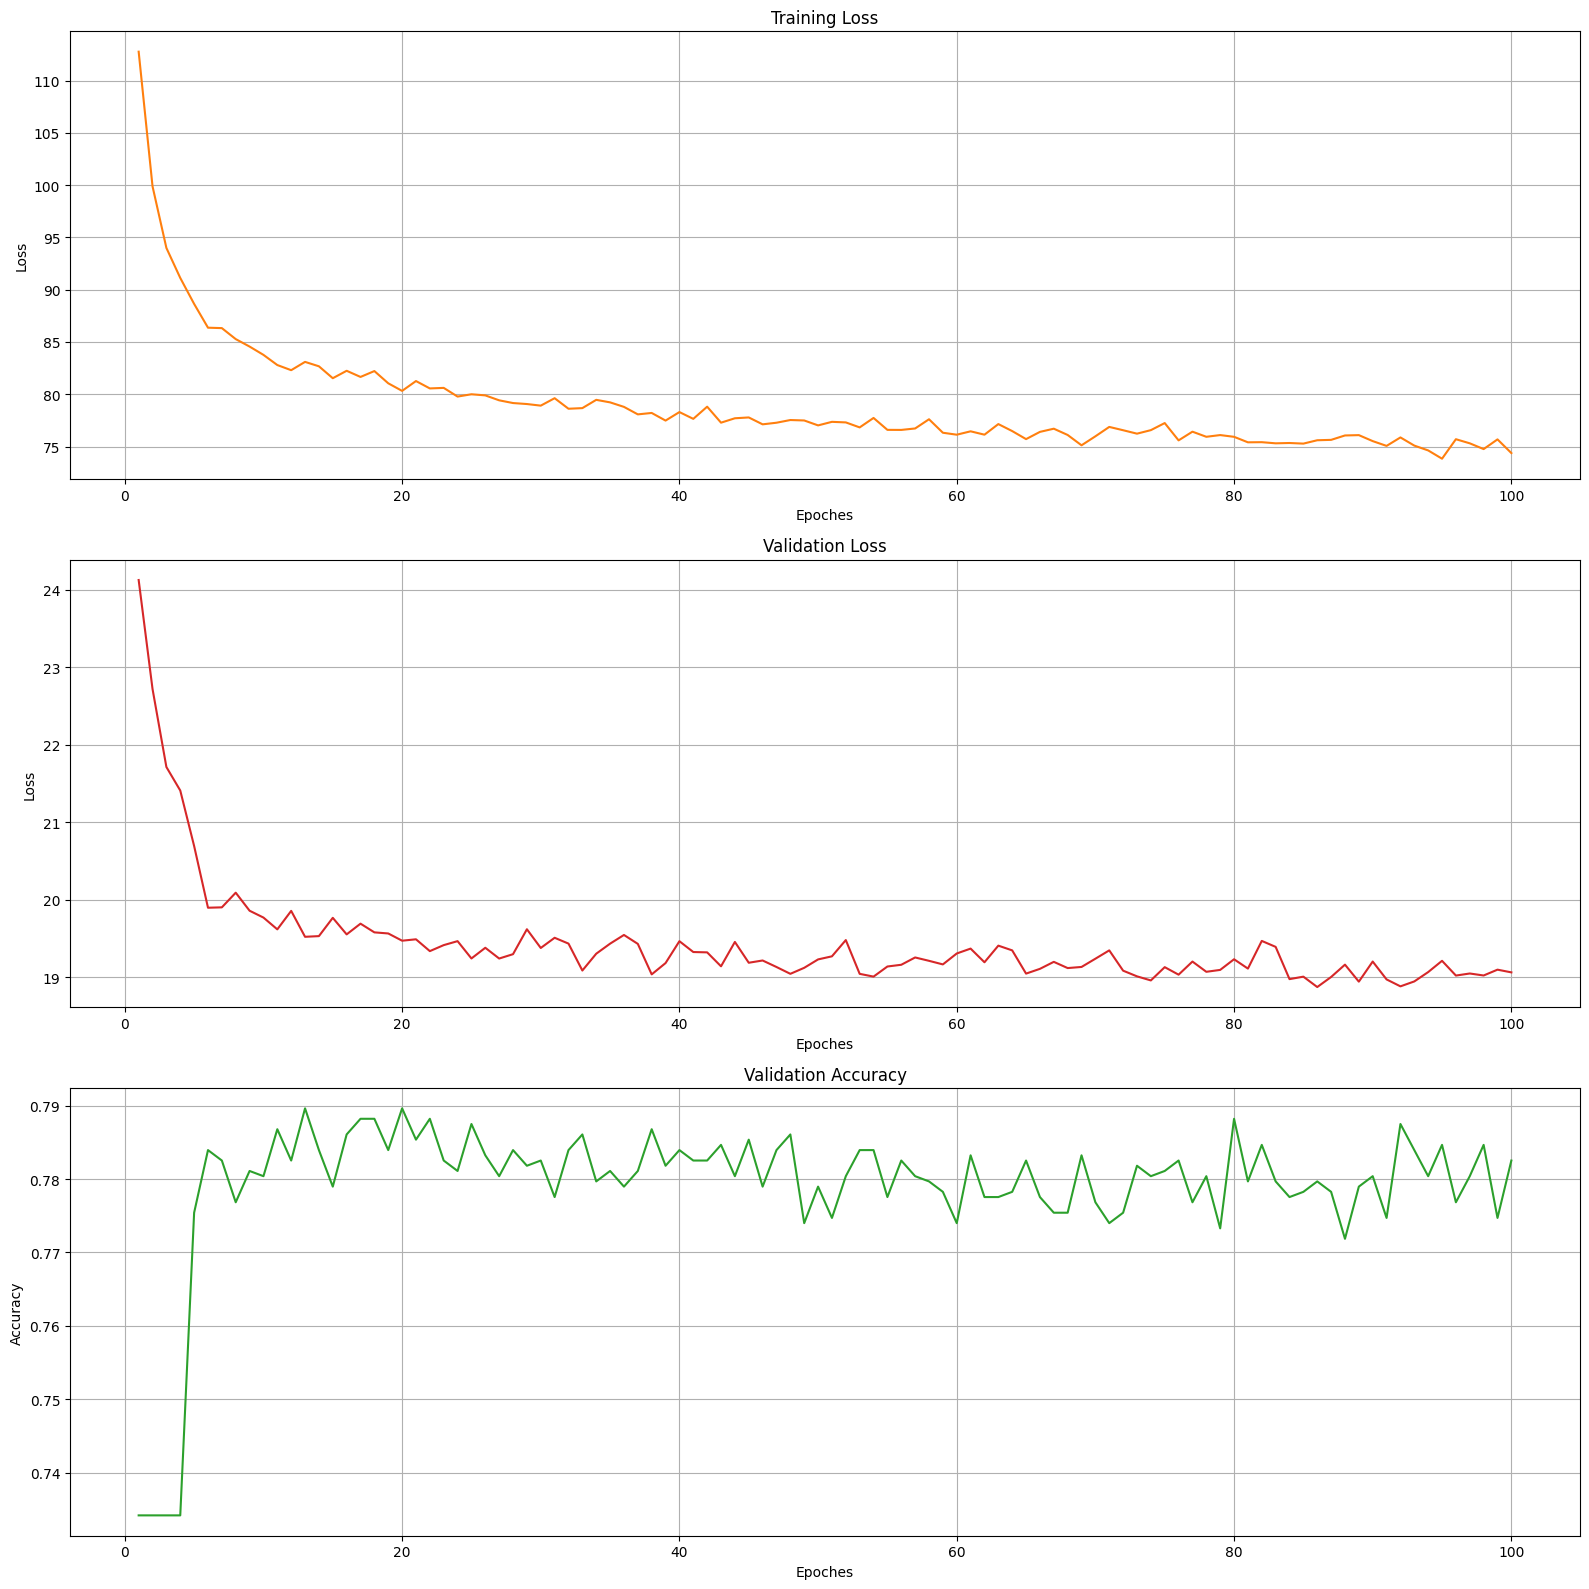

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ChurnModel(input_dim=X_train.shape[1])

train(model, train_loader, val_loader, device,epochs=100)